# Project 2 — Word embeddings and sequence models

**Question:** do pretrained word vectors and word order help classify WildGuardMix prompts?

Read and run Q1–Q6 in order. Each code cell names the question it addresses.
Each section ends with an answer based on its outputs, plus what remains uncertain.
The final section compares against saved Project 1 results.

We reuse the course embedding loader, encoders, classifier, batching and training loop.
Repeated project operations are in [`utils/p2/functions.py`](../utils/p2/functions.py).
The official questions remain in [`project.ipynb`](project.ipynb).

## Setup and experiment protocol

This notebook has exactly two evaluation phases.

1. **Development:** a disjoint 20% partition is split internally to study a
   small set of controlled design choices.
2. **Confirmation:** choices are locked before paired four-fold evaluation on
   the other 80%.

The primary vocabulary is fixed in advance: `PAD`, `UNK`, and every token seen
in the current training fold (`min_frequency=1`). GloVe supplies initial values,
not vocabulary membership. Pooling models use 10 epochs; LSTMs use the previously
motivated 5-epoch budget. All reported checkpoints are final-epoch checkpoints.

Earlier Project 2 experiments used the same source dataset and influenced the
five-epoch LSTM budget. Therefore, the current confirmation IDs are internally
disjoint from current development, but are not claimed to be historically unseen.
The official test set is never loaded here.


For execution, change one line in the setup cell:

- `run_mode = "cpu_test"` uses 100 examples per class and one epoch on CPU.
- `run_mode = "snellius"` restores the full data, scientific epoch budgets and CUDA requirement.


In [1]:
# Setup — imports, paths and reusable helpers
import hashlib
import json
import os
import platform
import random
import sys
import time
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

root = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "part2/clslib.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

default_hf_home = Path(os.environ.get("HF_HOME") or
                       Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache") / "huggingface")
os.environ.setdefault("HF_TOKEN_PATH", str(default_hf_home / "token"))
os.environ.setdefault("MPLCONFIGDIR", str(root / ".cache/matplotlib"))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

from part1 import experiment as p1_experiment
from part2 import clslib
from utils.p1.functions import TFIDF as P1TFIDF, encode_texts as p1_encode_texts
from utils.p2.functions import (
    ProjectWordTokenizer, classification_scores, clean_wildguard_prompts,
    coverage_by_label, embedding_coverage, experiment_signature, file_identity, input_features,
    load_fit_artifacts, make_toy_embeddings, nearest_words, prepare_fold,
    run_configuration, save_fit_artifacts, stratified_folds,
)

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Python:", sys.version.split()[0], "| torch:", torch.__version__, "| device:", device)
print("Platform:", platform.platform())


Python: 3.14.6 | torch: 2.15.0 | device: mps
Platform: macOS-27.2.1-arm64-arm-64bit-Mach-O


In [ ]:
# Setup — centralized experimental choices
use_toy_data = False  # Keep False for both the real CPU test and Snellius.
run_mode = "snellius"  # Change only this line to "snellius" for the full GPU run.
# cpu_test_examples_per_class = 8000
# cpu_test_epochs = 10

seed = 42
implementation_version = "p2-training-only-vocabulary-v2"
confirmation_seeds = [42, 142]
outer_split_folds = 5
development_inner_folds = 5
confirmation_num_folds = 4
embedding_dims = 50
pool_epochs = 10
lstm_epochs = 10
batch_size = 64
hidden_size = 64
dropout = 0.2
word_dropout = 0.1
learning_rate = 0.001
slow_embedding_learning_rate = 0.0001
weight_decay = 0.0001
primary_vocabulary_policy = "full_train"
primary_min_frequency = 1
p1_vocab_size = 3000
p1_min_frequency = 2
pinned_dataset_revision = "d29c47f41c8b51348b5c8e8c81c039b3132b66d1"
dataset_revision = pinned_dataset_revision
glove_path = Path(os.environ.get("P2_GLOVE_PATH", root / "part2/glove.2024.wikigiga.50d.zip"))
dataset_cache = Path(os.environ.get("P2_HF_DATASETS_CACHE", root / ".cache/huggingface/datasets"))
results_root = Path(os.environ.get("P2_RESULTS_ROOT", root / "part2/results"))
max_examples_per_class = None

if use_toy_data:
    run_mode = "toy"
    device = "cpu"
    confirmation_seeds = [seed]
    outer_split_folds, development_inner_folds, confirmation_num_folds = 3, 2, 2
    embedding_dims, pool_epochs, lstm_epochs = 12, 2, 2
    batch_size, hidden_size = 4, 8
elif run_mode == "cpu_test":
    device = "cpu"
    confirmation_seeds = [seed]
    outer_split_folds = development_inner_folds = confirmation_num_folds = 2
    pool_epochs = lstm_epochs = cpu_test_epochs
    batch_size, hidden_size = 32, 32
    max_examples_per_class = cpu_test_examples_per_class
elif run_mode == "snellius":
    if not torch.cuda.is_available():
        raise RuntimeError("Snellius mode requires a CUDA GPU allocation")
    device = "cuda"
else:
    raise ValueError('run_mode must be "cpu_test" or "snellius"')

if os.environ.get("SLURM_CPUS_PER_TASK"):
    torch.set_num_threads(int(os.environ["SLURM_CPUS_PER_TASK"]))
if device == "cuda":
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

implementation_identity = {
    "version": implementation_version,
    "p2_functions": file_identity(root / "utils/p2/functions.py"),
    "p2_clslib": file_identity(root / "part2/clslib.py"),
    "p2_experiment": file_identity(root / "part2/experiment.py"),
    "p1_functions": file_identity(root / "utils/p1/functions.py"),
    "p1_experiment": file_identity(root / "part1/experiment.py"),
    "runtime_versions": {
        "python": sys.version.split()[0], "torch": torch.__version__,
        "numpy": np.__version__, "scikit_learn": version("scikit-learn"),
    },
}

run_id = os.environ.get("P2_RUN_ID") or datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
results_folder = results_root / ("toy" if use_toy_data else "project2") / run_id
results_folder.mkdir(parents=True, exist_ok=True)
settings = dict(
    run_id=run_id, status="IN_PROGRESS", toy=use_toy_data, run_mode=run_mode,
    max_examples_per_class=max_examples_per_class, seed=seed,
    confirmation_seeds=confirmation_seeds, outer_split_folds=outer_split_folds,
    development_inner_folds=development_inner_folds,
    confirmation_num_folds=confirmation_num_folds, embedding_dims=embedding_dims,
    pool_epochs=pool_epochs, lstm_epochs=lstm_epochs, batch_size=batch_size,
    hidden_size=hidden_size, dropout=dropout, word_dropout=word_dropout,
    learning_rate=learning_rate, slow_embedding_learning_rate=slow_embedding_learning_rate,
    weight_decay=weight_decay, primary_vocabulary_policy=primary_vocabulary_policy,
    primary_min_frequency=primary_min_frequency, device=device,
    dataset_revision=dataset_revision, embedding_source=str(glove_path),
    official_test_accessed=False, checkpoint_rule="fixed final epoch",
    implementation_identity=implementation_identity,
    packages={name: version(name) for name in
              ["numpy", "pandas", "torch", "nltk", "datasets", "scikit-learn", "tokenizers"]},
)
(results_folder / "settings.json").write_text(json.dumps(settings, indent=2))
print("Run:", run_id, "| outputs:", results_folder)


Run: 20261119T235007628242Z | outputs: /Users/nivya21/NLP-P1/part2/results/project2/20261119T235007628242Z


## Q1. Is the embedding appropriate for this dataset?

**Hypothesis.** English GloVe 50d is compatible with most WildGuardMix word
occurrences, but specialised terms, unusual spellings and punctuation policies
will affect pretrained coverage.

We report GloVe coverage separately from training-vocabulary and model-row
coverage. The primary vocabulary always contains every training token. A
validation-only token maps to `UNK`, even when it exists in GloVe. `UNK` starts
from the same reproducible, scale-matched random row in pretrained and random
systems; it is not assumed to have learned a useful meaning.


In [3]:
# Q1a — preserve the approved WildGuardMix cleaning and create disjoint phases
if use_toy_data:
    dataset_provenance = {"source": "synthetic toy data", "revision": None}
    raw = pd.DataFrame([
        {"prompt": f"Please water the garden plants number {i}",
         "prompt_harm_label": "unharmful", "subcategory": "synthetic"}
        for i in range(12)
    ] + [
        {"prompt": f"Synthetic security misuse request number {i}",
         "prompt_harm_label": "harmful", "subcategory": "synthetic"}
        for i in range(12)
    ] + [
        {"prompt": "excluded", "prompt_harm_label": "harmful",
         "subcategory": " toxic_language_hate_speech "},
        {"prompt": "duplicate safe", "prompt_harm_label": "unharmful", "subcategory": "synthetic"},
        {"prompt": "duplicate safe", "prompt_harm_label": "unharmful", "subcategory": "synthetic"},
        {"prompt": "contradiction", "prompt_harm_label": "harmful", "subcategory": "synthetic"},
        {"prompt": "contradiction", "prompt_harm_label": "unharmful", "subcategory": "synthetic"},
    ])
else:
    # ``revision=`` is the supported Hugging Face provenance control. Builder
    # metadata verifies the requested repository/config/split without inferring
    # provenance from implementation-dependent cache paths.
    dataset = load_dataset(
        "allenai/wildguardmix", "wildguardtrain", split="train",
        revision=dataset_revision, token=True, cache_dir=str(dataset_cache))
    required_columns = {"prompt", "prompt_harm_label", "subcategory"}
    missing_columns = required_columns.difference(dataset.column_names)
    if missing_columns:
        raise ValueError(f"Pinned WildGuardMix revision is missing columns: {sorted(missing_columns)}")
    if not dataset.info.splits or "train" not in dataset.info.splits:
        raise ValueError("Pinned WildGuardMix dataset info does not expose the expected train split")
    dataset_provenance = {
        "repo_id": "allenai/wildguardmix", "config": "wildguardtrain",
        "split": "train", "requested_revision": dataset_revision,
        "builder_name": dataset.info.builder_name,
        "builder_config_name": dataset.info.config_name,
        "builder_version": str(dataset.info.version),
        "available_splits": sorted(dataset.info.splits),
    }
    raw = dataset.select_columns(sorted(required_columns)).to_pandas()

data, data_audit = clean_wildguard_prompts(raw)
display(pd.Series(data_audit, name="observed audit"))
historical_audit = {"original_rows": 86759, "excluded_category_rows": 3020,
                    "eligible_rows": 83739, "retained_rows": 46692}
audit_discrepancies = {
    key: {"historical": value, "observed": data_audit.get(key)}
    for key, value in historical_audit.items() if data_audit.get(key) != value
}
if not use_toy_data and dataset_revision == pinned_dataset_revision:
    print("Pinned-revision audit:", "matches historical audit" if not audit_discrepancies
          else audit_discrepancies)

if max_examples_per_class is not None:
    class_counts = data.groupby("label").size()
    if (class_counts < max_examples_per_class).any():
        raise ValueError(f"Requested sample exceeds available class counts: {class_counts.to_dict()}")
    sample = (data.groupby("label", group_keys=False)
              .sample(n=max_examples_per_class, random_state=seed)
              .sort_values("id").reset_index(drop=True))
    print(f"CPU TEST ONLY: {max_examples_per_class} examples per class")
else:
    sample = data.sort_values("id").reset_index(drop=True)
confirmation_indices, development_indices = stratified_folds(
    sample.label, outer_split_folds, seed)[0]
development_data = sample.iloc[development_indices].reset_index(drop=True)
confirmation_data = sample.iloc[confirmation_indices].reset_index(drop=True)
development_folds = stratified_folds(
    development_data.label, development_inner_folds, seed + 1)
dev_train_indices, dev_validation_indices = development_folds[0]
train = development_data.iloc[dev_train_indices].reset_index(drop=True)
validation = development_data.iloc[dev_validation_indices].reset_index(drop=True)
confirmation_folds = stratified_folds(
    confirmation_data.label, confirmation_num_folds, seed + 2)

assert set(development_data.id).isdisjoint(confirmation_data.id)
assert set(train.id).isdisjoint(validation.id)
print("Retained:", len(sample), "| harmful prevalence:", round(sample.label.mean(), 4))
print("Development:", len(development_data), "| confirmation:", len(confirmation_data))
print("Development inner train/validation:", len(train), "/", len(validation))

partition_table = sample[["id", "label"]].copy().set_index("id")
partition_table["phase"] = "development"
partition_table.loc[confirmation_data.id, "phase"] = "confirmation"
partition_table["confirmation_fold"] = -1
for fold, (_, indices) in enumerate(confirmation_folds):
    partition_table.loc[confirmation_data.iloc[indices].id, "confirmation_fold"] = fold
partition_table.reset_index().to_csv(results_folder / "partitions.csv", index=False)
(results_folder / "data_audit.json").write_text(json.dumps({
    "observed": data_audit, "historical_reference": historical_audit,
    "discrepancies": audit_discrepancies,
    "dataset_provenance": dataset_provenance}, indent=2))
settings["dataset_provenance"] = dataset_provenance


original_rows                  86759.00000
excluded_category_rows          3020.00000
missing_label_rows                 0.00000
eligible_rows                  83739.00000
empty_prompt_rows                 14.00000
contradictory_label_rows          30.00000
contradictory_label_groups        15.00000
duplicate_rows                 37003.00000
retained_rows                  46692.00000
retained_unharmful             23078.00000
retained_harmful               23614.00000
retained_harmful_prevalence        0.50574
Name: observed audit, dtype: float64

Pinned-revision audit: matches historical audit
CPU TEST ONLY: 8000 examples per class
Retained: 16000 | harmful prevalence: 0.5
Development: 8000 | confirmation: 8000
Development inner train/validation: 4000 / 4000


In [4]:
# Q1b — load GloVe and inspect tokenizer compatibility
if use_toy_data:
    embeddings = make_toy_embeddings(
        ["please", "water", "the", "garden", "plants", "synthetic", "security",
         "misuse", "request", "number", "safe", "dog", "bites", "man",
         "authentication", "phishing", "fraud"], embedding_dims, seed)
else:
    if not glove_path.exists():
        raise FileNotFoundError(f"Local GloVe archive required: {glove_path}")
    embeddings = clslib.PretrainedEmbeddings(str(glove_path), num_dims=embedding_dims)

tokenizer_keep = ProjectWordTokenizer(True, False, False, vocab=embeddings.vocab)
tokenizer_strip = ProjectWordTokenizer(True, True, False, vocab=embeddings.vocab)
examples = ["Don't bypass MFA.", "Explain phishing via example.com/login.",
            "Please help with my gardenn.", "A normal garden question."]
display(pd.DataFrame({
    "text": examples,
    "keep punctuation": [tokenizer_keep.tokens(text) for text in examples],
    "strip punctuation": [tokenizer_strip.tokens(text) for text in examples],
}))
print("GloVe rows/dimensions:", embeddings.vectors.shape)

# Content identities enter every neural-fit signature. The large archive is
# hashed once per notebook execution, not once per fit.
if use_toy_data:
    embedding_source_identity = {
        "kind": "toy", "seed": seed, "dimensions": embedding_dims,
        "vocabulary": list(embeddings.vocab),
        "vectors_sha256": hashlib.sha256(embeddings.vectors.tobytes()).hexdigest(),
    }
else:
    embedding_source_identity = {"kind": "file", **file_identity(glove_path)}
settings["embedding_source_identity"] = embedding_source_identity
(results_folder / "settings.json").write_text(json.dumps(settings, indent=2))


,text,keep punctuation,strip punctuation
0,Don't bypass MFA.,"[do, n't, bypass, mfa, .]","[don, t, bypass, mfa]"
1,Explain phishing via example.com/login.,"[explain, phishing, via, example.com/login, .]","[explain, phishing, via, example, com, login]"
2,Please help with my gardenn.,"[please, help, with, my, gardenn, .]","[please, help, with, my, gardenn]"
3,A normal garden question.,"[a, normal, garden, question, .]","[a, normal, garden, question]"


GloVe rows/dimensions: (1287615, 50)


2832

In [5]:
# Q1c — fit training-only vocabulary policies and report distinct coverage concepts
prepared_lookup = {
    "full_keep": prepare_fold(train, validation, embeddings, tokenizer_keep,
                              vocab_mode="full_train", min_frequency=1),
    "full_strip": prepare_fold(train, validation, embeddings, tokenizer_strip,
                               vocab_mode="full_train", min_frequency=1),
    "glove_restricted": prepare_fold(train, validation, embeddings, tokenizer_keep,
                                     vocab_mode="glove_restricted", min_frequency=1),
    "pruned_2": prepare_fold(train, validation, embeddings, tokenizer_keep,
                             vocab_mode="frequency_pruned", min_frequency=2),
    "pruned_5": prepare_fold(train, validation, embeddings, tokenizer_keep,
                             vocab_mode="frequency_pruned", min_frequency=5),
}
prepared = prepared_lookup["full_keep"]
coverage, glove_oov = embedding_coverage(train.prompt, tokenizer_keep, embeddings.vocab)
label_coverage = coverage_by_label(train, tokenizer_keep, embeddings.vocab)

coverage_rows = []
for name, fold_data in prepared_lookup.items():
    current_tokenizer = tokenizer_strip if name == "full_strip" else tokenizer_keep
    train_model_coverage, _ = embedding_coverage(train.prompt, current_tokenizer, fold_data["vocab"])
    validation_model_coverage, _ = embedding_coverage(
        validation.prompt, current_tokenizer, fold_data["vocab"])
    validation_train_coverage, _ = embedding_coverage(
        validation.prompt, current_tokenizer, fold_data["training_token_set"])
    coverage_rows.append({
        "policy": name, "training types": fold_data["training_types"],
        "model rows": len(fold_data["vocab"]),
        "GloVe-initialized rows": fold_data["dedicated_glove_rows"],
        "random word rows": fold_data["dedicated_random_rows"],
        "pruned training types": fold_data["pruned_training_types"],
        "training model coverage": train_model_coverage.token_coverage,
        "validation training-vocab coverage": validation_train_coverage.token_coverage,
        "validation model coverage": validation_model_coverage.token_coverage,
    })
coverage_table = pd.DataFrame(coverage_rows).set_index("policy")
display(coverage_table.round(4))
display(label_coverage.round(4))
display(glove_oov.head(15))
assert coverage_table.loc["full_keep", "training model coverage"] == 1.0
assert len(prepared["vocab"]) == prepared["training_types"] + 2
print(f"GloVe token/type coverage: {coverage.token_coverage:.2%} / {coverage.type_coverage:.2%}")
print("Full training coverage is 100%; this does not imply full GloVe or validation coverage.")

coverage.to_csv(results_folder / "glove_coverage.csv")
label_coverage.to_csv(results_folder / "glove_coverage_by_label.csv", index=False)
glove_oov.to_csv(results_folder / "glove_oov_counts.csv", index=False)
coverage_table.to_csv(results_folder / "vocabulary_policy_coverage.csv")


,training types,model rows,GloVe-initialized rows,random word rows,pruned training types,training model coverage,validation training-vocab coverage,validation model coverage
policy,,,,,,,,
full_keep,21493,21495,15240,6253,0,1.0000,0.9653,0.9653
full_strip,16712,16714,15775,937,0,1.0000,0.9720,0.9720
glove_restricted,21493,15242,15240,0,6253,0.9549,0.9653,0.9333
pruned_2,21493,11723,9523,2198,9772,0.9738,0.9653,0.9491
pruned_5,21493,5820,5123,695,15675,0.9317,0.9653,0.9149


,label,documents,tokens,types,token_coverage,type_coverage
0,0,2000.0,174116.0,14981.0,0.9523,0.7385
1,1,2000.0,198617.0,14421.0,0.9571,0.7517


,token,frequency
0,2.,220
1,3.,192
2,4.,135
3,name_1,112
4,story.,93
5,5.,90
6,real-world,90
7,guidelines.,90
8,step-by-step,86
9,content.,85


GloVe token/type coverage: 95.49% / 70.91%
Full training coverage is 100%; this does not imply full GloVe or validation coverage.


## Q2. What does the embedding capture, and where does it fail?

**Hypothesis.** GloVe captures distributional topic relationships, including
some security vocabulary, but does not encode harmful intent or context-dependent
word meaning. Static vectors assign one representation to each word type.

We inspect actual cosine similarities and nearest neighbours, then demonstrate
that mean pooling maps the same tokens in different orders to the same vector.
FastText is optional and is not simulated with a static `.vec` table.


In [6]:
# Q2a — real GloVe cosine similarities and nearest neighbours
probe_words = ["phishing", "fraud", "authentication", "garden", "bank"]
pairs = [("phishing", "fraud"), ("authentication", "security"),
         ("bank", "money"), ("garden", "plant")]
similarities = []
for left, right in pairs:
    if left in embeddings.vocab and right in embeddings.vocab:
        a, b = embeddings.embed_word(left), embeddings.embed_word(right)
        cosine = float(a @ b / max(np.linalg.norm(a) * np.linalg.norm(b), 1e-12))
        similarities.append({"left": left, "right": right, "cosine": cosine})
display(pd.DataFrame(similarities).round(4))
display(pd.DataFrame({"word": probe_words,
                      "in_GloVe": [word in embeddings.vocab for word in probe_words]}))
neighbours = pd.concat(
    [nearest_words(embeddings, word) for word in probe_words], ignore_index=True)
display(neighbours.round(4))
neighbours.to_csv(results_folder / "embedding_neighbours.csv", index=False)
pd.DataFrame(similarities).to_csv(results_folder / "embedding_similarities.csv", index=False)
print("Topical association is not evidence that GloVe understands harmful intent.")


,left,right,cosine
0,phishing,fraud,0.3875
1,authentication,security,0.2818
2,bank,money,0.7077
3,garden,plant,0.6251


,word,in_GloVe
0,phishing,True
1,fraud,True
2,authentication,True
3,garden,True
4,bank,True


,query,neighbour,cosine
0,phishing,scams,0.7580
1,phishing,scammers,0.7212
2,phishing,malware,0.7075
3,phishing,malicious,0.6956
4,phishing,astroturfing,0.6867
5,fraud,charges,0.8763
6,fraud,bribery,0.8589
7,fraud,alleged,0.8540
8,fraud,embezzlement,0.8407
9,fraud,alleging,0.8379


Topical association is not evidence that GloVe understands harmful intent.


In [7]:
# Q2b — mean pooling is exactly invariant to word order
sentences = ["dog bites man", "man bites dog"]
vectors = [np.mean([embeddings.embed_word(token) for token in tokenizer_keep.tokens(text)], axis=0)
           for text in sentences]
distance = float(np.linalg.norm(vectors[0] - vectors[1]))
print("Mean-vector distance for the order swap:", distance)
assert np.allclose(vectors[0], vectors[1], atol=1e-6)
print("The roles changed, but the pooled representation did not.")


Mean-vector distance for the order swap: 3.3618550787650747e-07
The roles changed, but the pooled representation did not.


## Q3. Which embed-and-pool choices matter?

Development experiments change one factor at a time:

1. pretrained versus random initialization on the same full training vocabulary;
2. mean versus sum pooling;
3. frozen versus tuned GloVe on the same GloVe-restricted vocabulary;
4. full, GloVe-restricted and frequency-pruned vocabulary policies;
5. punctuation policy and embedding learning rate.

Vocabulary-policy comparisons also change representational capacity and parameter
count; they are not interpreted as isolated initialization effects.

The matched Project 1 reference is exactly BPE(3000, min frequency 2) + TF-IDF
+ logistic regression. It is run on the same confirmation folds in Q5. That
comparison measures complete systems; only P2 pretrained versus P2 random isolates
pretrained initialization.


In [8]:
# Q3a — controlled development matrix and restart-safe fit wrapper
common = dict(hidden_size=hidden_size, classifier_width=hidden_size, dropout=dropout)
pool_configs = [
    dict(name="mean_pretrained", data_key="full_keep", encoder="mean",
         initialization="pretrained", frozen=False, embedding_learning_rate=learning_rate,
         epochs=pool_epochs, **common),
    dict(name="mean_random", data_key="full_keep", encoder="mean",
         initialization="random", frozen=False, embedding_learning_rate=learning_rate,
         epochs=pool_epochs, **common),
    dict(name="sum_pretrained", data_key="full_keep", encoder="sum",
         initialization="pretrained", frozen=False, embedding_learning_rate=learning_rate,
         epochs=pool_epochs, **common),
    dict(name="mean_glove_frozen", data_key="glove_restricted", encoder="mean",
         initialization="pretrained", frozen=True, epochs=pool_epochs, **common),
    dict(name="mean_glove_tuned", data_key="glove_restricted", encoder="mean",
         initialization="pretrained", frozen=False, embedding_learning_rate=learning_rate,
         epochs=pool_epochs, **common),
    dict(name="mean_pruned_2", data_key="pruned_2", encoder="mean",
         initialization="pretrained", frozen=False, embedding_learning_rate=learning_rate,
         epochs=pool_epochs, **common),
    dict(name="mean_pruned_5", data_key="pruned_5", encoder="mean",
         initialization="pretrained", frozen=False, embedding_learning_rate=learning_rate,
         epochs=pool_epochs, **common),
    dict(name="mean_strip_punctuation", data_key="full_strip", encoder="mean",
         initialization="pretrained", frozen=False, embedding_learning_rate=learning_rate,
         epochs=pool_epochs, **common),
    dict(name="mean_slow_embedding_lr", data_key="full_keep", encoder="mean",
         initialization="pretrained", frozen=False,
         embedding_learning_rate=slow_embedding_learning_rate,
         epochs=pool_epochs, **common),
]
fit_options = dict(batch_size=batch_size, learning_rate=learning_rate,
                   weight_decay=weight_decay, device=device)

def execute_fit(fold_data, config, *, phase, fold, model_seed):
    resolved = {**config, "phase": phase, "fold": fold, "seed": model_seed,
                "checkpoint_rule": "fixed final epoch",
                "dataset_revision": dataset_revision,
                "dataset_provenance": dataset_provenance,
                "embedding_source_identity": embedding_source_identity,
                "implementation_identity": implementation_identity,
                "tokenizer_policy": fold_data["tokenizer_policy"],
                "vocab_mode": fold_data["vocab_mode"],
                "min_frequency": fold_data["min_frequency"],
                "embedding_dimensions": fold_data["embedding_dims"],
                "base_optimizer": {"name": "AdamW", "learning_rate": learning_rate,
                                   "weight_decay": weight_decay,
                                   "batch_size": batch_size,
                                   "shuffle": True},
                "device": device}
    training_keys = [f"{row.id}:{row.label}" for row in fold_data["train"].itertuples()]
    validation_keys = [f"{row.id}:{row.label}" for row in fold_data["validation"].itertuples()]
    signature = experiment_signature(
        resolved, training_keys, validation_keys,
        seed=model_seed, epochs=config["epochs"])
    cached = load_fit_artifacts(results_folder, signature)
    if cached is None:
        score, history, predictions = run_configuration(
            fold_data, config, seed=model_seed, epochs=config["epochs"], **fit_options)
        score.update(phase=phase, fold=fold, signature=signature,
                     checkpoint_rule="fixed final epoch")
        history["phase"], history["fold"], history["signature"] = phase, fold, signature
        history["checkpoint_rule"] = "fixed final epoch"
        history["encoder"] = config["encoder"]
        history["initialization"] = config["initialization"]
        history["vocab_mode"] = fold_data["vocab_mode"]
        history["frozen_embeddings"] = config["frozen"]
        history["word_dropout"] = config.get("word_dropout", 0.0)
        predictions["phase"], predictions["fold"], predictions["signature"] = phase, fold, signature
        save_fit_artifacts(results_folder, signature, score, history, predictions)
    else:
        score, history, predictions = cached
        print("Reused completed fit:", phase, fold, config["name"], model_seed)
    return score, history, predictions

controlled_matrix = pd.DataFrame([
    ["Pretraining", "mean_random", "mean_pretrained", "known rows: random → GloVe", "development"],
    ["Pooling", "mean_pretrained", "sum_pretrained", "mean → sum", "development"],
    ["Fine-tuning", "mean_glove_frozen", "mean_glove_tuned", "frozen → trainable", "development"],
    ["Vocabulary", "mean_glove_tuned", "mean_pretrained", "restricted → full train", "development"],
    ["Pruning", "mean_pretrained", "mean_pruned_2/5", "minimum frequency", "development"],
    ["Tokenization", "mean_pretrained", "mean_strip_punctuation", "punctuation", "development"],
], columns=["question", "baseline", "comparison", "changed factor", "evaluation"])
display(controlled_matrix)


,question,baseline,comparison,changed factor,evaluation
0,Pretraining,mean_random,mean_pretrained,known rows: random → GloVe,development
1,Pooling,mean_pretrained,sum_pretrained,mean → sum,development
2,Fine-tuning,mean_glove_frozen,mean_glove_tuned,frozen → trainable,development
3,Vocabulary,mean_glove_tuned,mean_pretrained,restricted → full train,development
4,Pruning,mean_pretrained,mean_pruned_2/5,minimum frequency,development
5,Tokenization,mean_pretrained,mean_strip_punctuation,punctuation,development


In [9]:
# Q3b — execute development comparisons and lock non-vocabulary choices
development_score_rows, development_histories, development_prediction_tables = [], [], []
for config in pool_configs:
    score, history, predictions = execute_fit(
        prepared_lookup[config["data_key"]], config,
        phase="development", fold=0, model_seed=seed)
    development_score_rows.append(score)
    development_histories.append(history)
    development_prediction_tables.append(predictions)

pool_results = pd.DataFrame(development_score_rows).set_index("name")
display(pool_results[["vocab_mode", "vocabulary_size", "glove_rows", "random_rows",
                      "embedding_learning_rate", "macro_f1", "accuracy",
                      "harmful_recall", "benign_fpr"]].round(4))
for a, b, label in [
    ("mean_random", "mean_pretrained", "pretrained initialization"),
    ("mean_pretrained", "sum_pretrained", "sum rather than mean pooling"),
    ("mean_glove_frozen", "mean_glove_tuned", "fine-tuning matched GloVe rows"),
    ("mean_glove_tuned", "mean_pretrained", "full rather than GloVe-restricted vocabulary"),
    ("mean_pretrained", "mean_pruned_2", "minimum frequency 2"),
    ("mean_pretrained", "mean_pruned_5", "minimum frequency 5"),
]:
    print(label, f": {pool_results.loc[b, 'macro_f1'] - pool_results.loc[a, 'macro_f1']:+.4f}")

# Full training vocabulary remains primary regardless of pruning results.
selected_remove_punct = bool(
    pool_results.loc["mean_strip_punctuation", "macro_f1"]
    > pool_results.loc["mean_pretrained", "macro_f1"])
selected_embedding_learning_rate = (
    slow_embedding_learning_rate
    if pool_results.loc["mean_slow_embedding_lr", "macro_f1"]
       > pool_results.loc["mean_pretrained", "macro_f1"] else learning_rate)
selected_tokenizer = tokenizer_strip if selected_remove_punct else tokenizer_keep
settings.update(selected_remove_punctuation=selected_remove_punct,
                selected_embedding_learning_rate=selected_embedding_learning_rate)
print("Locked later choices:", {"vocabulary": "full_train/min_frequency=1",
      "remove punctuation": selected_remove_punct,
      "embedding learning rate": selected_embedding_learning_rate})


mean_pretrained | seed 42 | epoch 1/10 | validation F1 0.6858
mean_pretrained | seed 42 | epoch 2/10 | validation F1 0.7000
mean_pretrained | seed 42 | epoch 3/10 | validation F1 0.7561
mean_pretrained | seed 42 | epoch 4/10 | validation F1 0.7638
mean_pretrained | seed 42 | epoch 5/10 | validation F1 0.7737
mean_pretrained | seed 42 | epoch 6/10 | validation F1 0.7858
mean_pretrained | seed 42 | epoch 7/10 | validation F1 0.7840
mean_pretrained | seed 42 | epoch 8/10 | validation F1 0.7847
mean_pretrained | seed 42 | epoch 9/10 | validation F1 0.7884
mean_pretrained | seed 42 | epoch 10/10 | validation F1 0.7579
mean_random | seed 42 | epoch 1/10 | validation F1 0.6820
mean_random | seed 42 | epoch 2/10 | validation F1 0.7210
mean_random | seed 42 | epoch 3/10 | validation F1 0.7519
mean_random | seed 42 | epoch 4/10 | validation F1 0.7683
mean_random | seed 42 | epoch 5/10 | validation F1 0.7800
mean_random | seed 42 | epoch 6/10 | validation F1 0.7798
mean_random | seed 42 | epoch 7

,vocab_mode,vocabulary_size,glove_rows,random_rows,embedding_learning_rate,macro_f1,accuracy,harmful_recall,benign_fpr
name,,,,,,,,,
mean_pretrained,full_train,21495,15240,6253,0.0010,0.7579,0.7628,0.9050,0.3795
mean_random,full_train,21495,15240,6253,0.0010,0.7826,0.7830,0.7400,0.1740
sum_pretrained,full_train,21495,15240,6253,0.0010,0.7812,0.7815,0.8170,0.2540
mean_glove_frozen,glove_restricted,15242,15240,0,0.0010,0.7149,0.7153,0.6790,0.2485
mean_glove_tuned,glove_restricted,15242,15240,0,0.0010,0.7959,0.7965,0.8485,0.2555
mean_pruned_2,frequency_pruned,11723,9523,2198,0.0010,0.7980,0.7982,0.8330,0.2365
mean_pruned_5,frequency_pruned,5820,5123,695,0.0010,0.7969,0.7972,0.8405,0.2460
mean_strip_punctuation,full_train,16714,15775,937,0.0010,0.7666,0.7700,0.8900,0.3500
mean_slow_embedding_lr,full_train,21495,15240,6253,0.0001,0.7232,0.7252,0.8105,0.3600


pretrained initialization : -0.0247
sum rather than mean pooling : +0.0234
fine-tuning matched GloVe rows : +0.0811
full rather than GloVe-restricted vocabulary : -0.0381
minimum frequency 2 : +0.0402
minimum frequency 5 : +0.0390
Locked later choices: {'vocabulary': 'full_train/min_frequency=1', 'remove punctuation': True, 'embedding learning rate': 0.001}


## Q4. Does a recurrent encoder help?

**Hypotheses.** An LSTM may improve on pooling because it models sequence order,
but it also changes parameterization and optimization. Word dropout may reduce
overfitting. Pretraining should matter more with less labelled data.

We compare LSTM with a five-epoch mean-pooling control, frozen/tuned embeddings
under the same GloVe-restricted vocabulary, full/half training data with separately
fitted vocabularies, pretrained/random initialization at both data sizes,
and LSTM with/without course word dropout. We do not claim
that an LSTM difference isolates word order alone.


In [ ]:
# Q4a — recurrent comparisons with fixed five-epoch checkpoints
selected_primary = prepare_fold(
    train, validation, embeddings, selected_tokenizer,
    vocab_mode="full_train", min_frequency=1)
selected_glove_restricted = prepare_fold(
    train, validation, embeddings, selected_tokenizer,
    vocab_mode="glove_restricted", min_frequency=1)
small_train = (train.groupby("label", group_keys=False)
               .sample(frac=0.5, random_state=seed)
               .sort_values("id").reset_index(drop=True))
small_primary = prepare_fold(
    small_train, validation, embeddings, selected_tokenizer,
    vocab_mode="full_train", min_frequency=1)
lstm_lookup = {"primary": selected_primary, "restricted": selected_glove_restricted,
               "half": small_primary}
lstm_configs = [
    dict(name="mean_pretrained_10ep", data_key="primary", encoder="mean",
         initialization="pretrained", frozen=False,
         embedding_learning_rate=selected_embedding_learning_rate,
         epochs=lstm_epochs, **common),
    dict(name="lstm_pretrained", data_key="primary", encoder="lstm",
         initialization="pretrained", frozen=False, word_dropout=0.0,
         embedding_learning_rate=selected_embedding_learning_rate,
         epochs=lstm_epochs, **common),
    dict(name="lstm_random", data_key="primary", encoder="lstm",
         initialization="random", frozen=False, word_dropout=0.0,
         embedding_learning_rate=selected_embedding_learning_rate,
         epochs=lstm_epochs, **common),
    dict(name="lstm_word_dropout", data_key="primary", encoder="lstm",
         initialization="pretrained", frozen=False, word_dropout=word_dropout,
         embedding_learning_rate=selected_embedding_learning_rate,
         epochs=lstm_epochs, **common),
    dict(name="lstm_glove_frozen", data_key="restricted", encoder="lstm",
         initialization="pretrained", frozen=True, word_dropout=0.0,
         epochs=lstm_epochs, **common),
    dict(name="lstm_glove_tuned", data_key="restricted", encoder="lstm",
         initialization="pretrained", frozen=False, word_dropout=0.0,
         embedding_learning_rate=selected_embedding_learning_rate,
         epochs=lstm_epochs, **common),
    dict(name="lstm_half_pretrained", data_key="half", encoder="lstm",
         initialization="pretrained", frozen=False, word_dropout=0.0,
         embedding_learning_rate=selected_embedding_learning_rate,
         epochs=lstm_epochs, **common),
    dict(name="lstm_half_random", data_key="half", encoder="lstm",
         initialization="random", frozen=False, word_dropout=0.0,
         embedding_learning_rate=selected_embedding_learning_rate,
         epochs=lstm_epochs, **common),
]
for config in lstm_configs:
    score, history, predictions = execute_fit(
        lstm_lookup[config["data_key"]], config,
        phase="development", fold=0, model_seed=seed)
    development_score_rows.append(score)
    development_histories.append(history)
    development_prediction_tables.append(predictions)

lstm_results = pd.DataFrame(development_score_rows).set_index("name")
display(lstm_results.loc[[config["name"] for config in lstm_configs],
    ["n_train", "vocab_mode", "initialization", "macro_f1", "accuracy",
     "harmful_recall", "benign_fpr", "word_dropout", "trainable_parameters"]].round(4))
for a, b, label in [
    ("mean_pretrained_5ep", "lstm_pretrained", "LSTM versus budget-matched mean"),
    ("lstm_glove_frozen", "lstm_glove_tuned", "LSTM embedding fine-tuning"),
    ("lstm_random", "lstm_pretrained", "pretraining at 100% training data"),
    ("lstm_half_random", "lstm_half_pretrained", "pretraining at 50% training data"),
    ("lstm_half_pretrained", "lstm_pretrained", "100% versus 50% data, pretrained"),
    ("lstm_pretrained", "lstm_word_dropout", "LSTM word dropout"),
]:
    print(label, f": {lstm_results.loc[b, 'macro_f1'] - lstm_results.loc[a, 'macro_f1']:+.4f}")

lstm_data_size_initialization = pd.DataFrame([
    {"training_fraction": 1.0, "initialization": "pretrained",
     **lstm_results.loc["lstm_pretrained", ["macro_f1", "accuracy"]].to_dict()},
    {"training_fraction": 1.0, "initialization": "random",
     **lstm_results.loc["lstm_random", ["macro_f1", "accuracy"]].to_dict()},
    {"training_fraction": 0.5, "initialization": "pretrained",
     **lstm_results.loc["lstm_half_pretrained", ["macro_f1", "accuracy"]].to_dict()},
    {"training_fraction": 0.5, "initialization": "random",
     **lstm_results.loc["lstm_half_random", ["macro_f1", "accuracy"]].to_dict()},
])
display(lstm_data_size_initialization.round(4))
print("This development experiment is Tutorial 2-inspired and does not alter the locked confirmation shortlist.")


mean_pretrained_5ep | seed 42 | epoch 1/10 | validation F1 0.6842
mean_pretrained_5ep | seed 42 | epoch 2/10 | validation F1 0.7176
mean_pretrained_5ep | seed 42 | epoch 3/10 | validation F1 0.7574
mean_pretrained_5ep | seed 42 | epoch 4/10 | validation F1 0.7676
mean_pretrained_5ep | seed 42 | epoch 5/10 | validation F1 0.7805
mean_pretrained_5ep | seed 42 | epoch 6/10 | validation F1 0.7888
mean_pretrained_5ep | seed 42 | epoch 7/10 | validation F1 0.7934
mean_pretrained_5ep | seed 42 | epoch 8/10 | validation F1 0.7819
mean_pretrained_5ep | seed 42 | epoch 9/10 | validation F1 0.7924
mean_pretrained_5ep | seed 42 | epoch 10/10 | validation F1 0.7666
lstm_pretrained | seed 42 | epoch 1/10 | validation F1 0.6574
lstm_pretrained | seed 42 | epoch 2/10 | validation F1 0.7262
lstm_pretrained | seed 42 | epoch 3/10 | validation F1 0.7384
lstm_pretrained | seed 42 | epoch 4/10 | validation F1 0.7406
lstm_pretrained | seed 42 | epoch 5/10 | validation F1 0.7615
lstm_pretrained | seed 42 | e

,n_train,vocab_mode,initialization,macro_f1,accuracy,harmful_recall,benign_fpr,word_dropout,trainable_parameters
name,,,,,,,,,
mean_pretrained_5ep,4000,full_train,pretrained,0.7666,0.7700,0.8900,0.3500,NaN,838454
lstm_pretrained,4000,full_train,pretrained,0.7181,0.7260,0.8935,0.4415,0.0,848630
lstm_random,4000,full_train,random,0.7267,0.7282,0.8045,0.3480,0.0,848630
lstm_word_dropout,4000,full_train,pretrained,0.7558,0.7598,0.8865,0.3670,0.1,848630
lstm_glove_frozen,4000,glove_restricted,pretrained,0.6917,0.6968,0.8250,0.4315,0.0,12930
lstm_glove_tuned,4000,glove_restricted,pretrained,0.7662,0.7668,0.8170,0.2835,0.0,801780
lstm_half_pretrained,2000,full_train,pretrained,0.7151,0.7188,0.8320,0.3945,0.0,622230
lstm_half_random,2000,full_train,random,0.6851,0.6852,0.6650,0.2945,0.0,622230


LSTM versus budget-matched mean : -0.0485
LSTM embedding fine-tuning : +0.0745
pretraining at 100% training data : -0.0086
pretraining at 50% training data : +0.0300
100% versus 50% data, pretrained : +0.0030
LSTM word dropout : +0.0377


,training_fraction,initialization,macro_f1,accuracy
0,1.0,pretrained,0.7181,0.7260
1,1.0,random,0.7267,0.7282
2,0.5,pretrained,0.7151,0.7188
3,0.5,random,0.6851,0.6852


This development experiment is Tutorial 2-inspired and does not alter the locked confirmation shortlist.


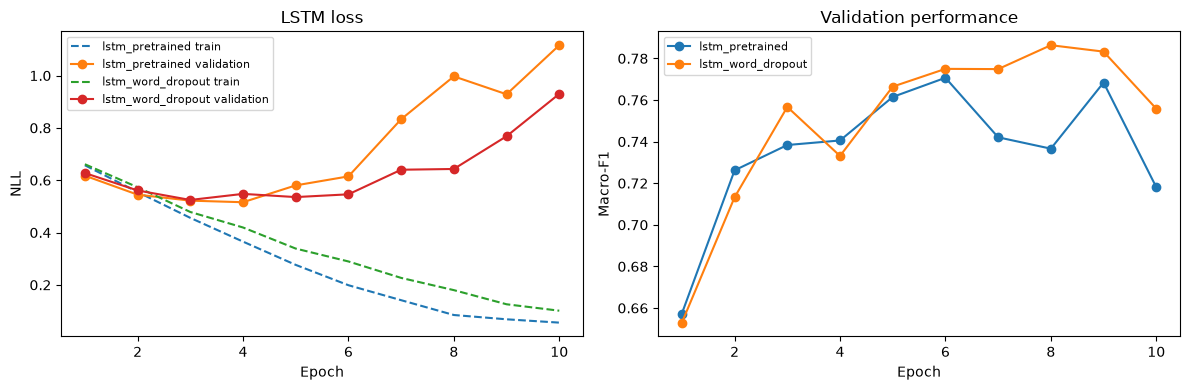

Curves are diagnostic; the final epoch remains the fixed checkpoint.


In [11]:
# Q4b — development learning curves for overfitting diagnosis
development_history = pd.concat(development_histories, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for system in ["lstm_pretrained", "lstm_word_dropout"]:
    curve = development_history[development_history.system == system]
    axes[0].plot(curve.epoch, curve.train_loss, "--", label=f"{system} train")
    axes[0].plot(curve.epoch, curve.validation_loss, marker="o", label=f"{system} validation")
    axes[1].plot(curve.epoch, curve.macro_f1, marker="o", label=system)
axes[0].set(title="LSTM loss", xlabel="Epoch", ylabel="NLL")
axes[1].set(title="Validation performance", xlabel="Epoch", ylabel="Macro-F1")
for axis in axes:
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(results_folder / "development_lstm_curves.png", dpi=150)
plt.show()
print("Curves are diagnostic; the final epoch remains the fixed checkpoint.")


## Q5. How much evidence supports our choices?

Before confirmation, we save a locked manifest. The primary vocabulary remains
full training vocabulary; pruning results cannot change it. Confirmation uses
the same folds for every system and two seeds for neural models (one in toy mode).

We report seed/fold-resolved scores, seed-averaged fold means, descriptive fold
SDs, paired differences and pooled out-of-fold metrics. Folds overlap in training
data, so their SD is not a standard error. Confirmation is internally clean but
not historically untouched because earlier experiments used this source dataset.
The cleaned dataset and top-level split are fixed, so variation from resampling a
new dataset is not measured; two seeds provide only a small initialization check.
No winner selected after confirmation is presented as an unbiased post-selection estimate.


In [12]:
# Q5a — lock the protocol, then run paired confirmation with immediate saving
confirmation_configs = [
    dict(name="mean_pretrained", encoder="mean", initialization="pretrained",
         frozen=False, embedding_learning_rate=selected_embedding_learning_rate,
         epochs=pool_epochs, **common),
    dict(name="mean_random", encoder="mean", initialization="random",
         frozen=False, embedding_learning_rate=selected_embedding_learning_rate,
         epochs=pool_epochs, **common),
    dict(name="mean_pretrained_5ep", encoder="mean", initialization="pretrained",
         frozen=False, embedding_learning_rate=selected_embedding_learning_rate,
         epochs=lstm_epochs, **common),
    dict(name="lstm_pretrained", encoder="lstm", initialization="pretrained",
         frozen=False, word_dropout=0.0,
         embedding_learning_rate=selected_embedding_learning_rate,
         epochs=lstm_epochs, **common),
    dict(name="lstm_word_dropout", encoder="lstm", initialization="pretrained",
         frozen=False, word_dropout=word_dropout,
         embedding_learning_rate=selected_embedding_learning_rate,
         epochs=lstm_epochs, **common),
]
locked_manifest = {
    "status": "LOCKED_BEFORE_CONFIRMATION", "vocabulary_policy": "full_train",
    "min_frequency": 1, "remove_punctuation": selected_remove_punct,
    "embedding_learning_rate": selected_embedding_learning_rate,
    "checkpoint_rule": "fixed final epoch", "confirmation_seeds": confirmation_seeds,
    "confirmation_configurations": confirmation_configs,
    "base_optimizer": {"name": "AdamW", "learning_rate": learning_rate,
                       "weight_decay": weight_decay, "batch_size": batch_size},
    "tokenizer_policy": selected_primary["tokenizer_policy"],
    "embedding_source_identity": embedding_source_identity,
    "implementation_identity": implementation_identity,
}
(results_folder / "locked_confirmation_manifest.json").write_text(
    json.dumps(locked_manifest, indent=2))

confirmation_score_rows, confirmation_histories = [], []
confirmation_prediction_tables, confirmation_feature_tables = [], []
for outer_fold, (train_indices, validation_indices) in enumerate(confirmation_folds):
    fold_train = confirmation_data.iloc[train_indices].reset_index(drop=True)
    fold_validation = confirmation_data.iloc[validation_indices].reset_index(drop=True)
    fold_prepared = prepare_fold(
        fold_train, fold_validation, embeddings, selected_tokenizer,
        vocab_mode="full_train", min_frequency=1)

    for model_seed in confirmation_seeds:
        for config in confirmation_configs:
            score, history, predictions = execute_fit(
                fold_prepared, config, phase="confirmation",
                fold=outer_fold, model_seed=model_seed)
            confirmation_score_rows.append(score)
            confirmation_histories.append(history)
            confirmation_prediction_tables.append(predictions)

    # One matched Project 1 reference per fold: BPE + TF-IDF + logistic regression.
    p1_config = {"name": "p1_logistic_tfidf", "BPE_vocab_size": p1_vocab_size,
                 "BPE_min_frequency": p1_min_frequency, "C": 1.0,
                 "solver": "lbfgs", "phase": "confirmation", "fold": outer_fold,
                 "dataset_revision": dataset_revision,
                 "dataset_provenance": dataset_provenance,
                 "implementation_identity": implementation_identity,
                 "tokenizer": {"type": "BPE", "vocab_size": p1_vocab_size,
                               "min_frequency": p1_min_frequency},
                 "optimizer": {"type": "lbfgs", "C": 1.0,
                               "max_iter": 1000, "random_state": seed},
                 "implementation": "matched_p1_reference_v2"}
    p1_training_keys = [f"{row.id}:{row.label}" for row in fold_train.itertuples()]
    p1_validation_keys = [f"{row.id}:{row.label}" for row in fold_validation.itertuples()]
    p1_signature = experiment_signature(
        p1_config, p1_training_keys, p1_validation_keys, seed=seed, epochs=0)
    cached = load_fit_artifacts(results_folder, p1_signature)
    if cached is None:
        train_texts, validation_texts = fold_train.prompt.tolist(), fold_validation.prompt.tolist()
        p1_tokenizer = p1_experiment.train_tokenizer(
            train_texts, p1_vocab_size, p1_min_frequency)
        p1_tfidf = P1TFIDF(p1_tokenizer).fit(train_texts)
        X_train = p1_encode_texts(train_texts, p1_tfidf)
        X_validation = p1_encode_texts(validation_texts, p1_tfidf)
        started = time.perf_counter()
        p1_model = LogisticRegression(
            C=1.0, solver="lbfgs", max_iter=1000, random_state=seed)
        p1_model.fit(X_train, fold_train.label.to_numpy())
        probabilities = p1_model.predict_proba(X_validation)
        predicted = probabilities.argmax(axis=1)
        p1_score = {"name": "p1_logistic_tfidf", "phase": "confirmation",
                    "fold": outer_fold, "seed": seed, "epochs": 0,
                    "n_train": len(fold_train), "n_validation": len(fold_validation),
                    "fit_seconds": time.perf_counter() - started,
                    "signature": p1_signature, "checkpoint_rule": "solver convergence",
                    **classification_scores(fold_validation.label, predicted)}
        p1_history = pd.DataFrame([{"system": "p1_logistic_tfidf", "phase": "confirmation",
                                    "fold": outer_fold, "seed": seed, "epoch": 0,
                                    "checkpoint_rule": "solver convergence"}])
        p1_predictions = pd.DataFrame({
            "id": fold_validation.id, "gold": fold_validation.label,
            "system": "p1_logistic_tfidf", "seed": seed, "fold": outer_fold,
            "phase": "confirmation", "prediction": predicted,
            "probability_harmful": probabilities[:, 1],
            "confidence": probabilities.max(axis=1), "signature": p1_signature})
        save_fit_artifacts(results_folder, p1_signature, p1_score, p1_history, p1_predictions)
    else:
        p1_score, p1_history, p1_predictions = cached
    confirmation_score_rows.append(p1_score)
    confirmation_histories.append(p1_history)
    confirmation_prediction_tables.append(p1_predictions)

    fold_features = pd.DataFrame([
        input_features(text, selected_tokenizer, fold_prepared["training_token_set"],
                       fold_prepared["vocab"], embeddings.vocab)
        for text in fold_validation.prompt])
    fold_features["id"] = fold_validation.id.to_numpy()
    fold_features["fold"] = outer_fold
    confirmation_feature_tables.append(fold_features)
    print("Completed confirmation fold", outer_fold)

confirmation_scores = pd.DataFrame(confirmation_score_rows)
confirmation_history = pd.concat(confirmation_histories, ignore_index=True)
confirmation_predictions = pd.concat(confirmation_prediction_tables, ignore_index=True)
confirmation_features = pd.concat(confirmation_feature_tables, ignore_index=True)

neural_names = [config["name"] for config in confirmation_configs]
for system in neural_names:
    counts = confirmation_predictions[confirmation_predictions.system == system].groupby("id").size()
    assert counts.eq(len(confirmation_seeds)).all()
p1_counts = confirmation_predictions[
    confirmation_predictions.system == "p1_logistic_tfidf"].groupby("id").size()
assert p1_counts.eq(1).all()
assert set(p1_counts.index) == set(confirmation_data.id)
assert set(confirmation_predictions.id) == set(confirmation_data.id)

# Q3's single matched P1 reference is reported here under the locked Q5 protocol.
neural_scores = confirmation_scores[confirmation_scores.name != "p1_logistic_tfidf"]
fold_mean_scores = neural_scores.groupby(["name", "fold"], as_index=False).agg(
    macro_f1=("macro_f1", "mean"), accuracy=("accuracy", "mean"),
    harmful_recall=("harmful_recall", "mean"), benign_fpr=("benign_fpr", "mean"))
p1_fold_scores = confirmation_scores[
    confirmation_scores.name == "p1_logistic_tfidf"][fold_mean_scores.columns]
all_fold_scores = pd.concat([fold_mean_scores, p1_fold_scores], ignore_index=True)
confirmation_summary = all_fold_scores.groupby("name").agg(
    macro_f1_mean=("macro_f1", "mean"), macro_f1_fold_sd=("macro_f1", "std"),
    accuracy_mean=("accuracy", "mean"), harmful_recall_mean=("harmful_recall", "mean"),
    benign_fpr_mean=("benign_fpr", "mean"), folds=("fold", "nunique"),
).sort_values("macro_f1_mean", ascending=False)
display(confirmation_summary.round(4))
print("P1/P2 compares complete systems; mean_pretrained/mean_random isolates initialization.")


mean_pretrained | seed 42 | epoch 1/10 | validation F1 0.6801
mean_pretrained | seed 42 | epoch 2/10 | validation F1 0.7254
mean_pretrained | seed 42 | epoch 3/10 | validation F1 0.7351
mean_pretrained | seed 42 | epoch 4/10 | validation F1 0.7627
mean_pretrained | seed 42 | epoch 5/10 | validation F1 0.7757
mean_pretrained | seed 42 | epoch 6/10 | validation F1 0.7763
mean_pretrained | seed 42 | epoch 7/10 | validation F1 0.7845
mean_pretrained | seed 42 | epoch 8/10 | validation F1 0.7872
mean_pretrained | seed 42 | epoch 9/10 | validation F1 0.7897
mean_pretrained | seed 42 | epoch 10/10 | validation F1 0.7880
mean_random | seed 42 | epoch 1/10 | validation F1 0.6494
mean_random | seed 42 | epoch 2/10 | validation F1 0.6998
mean_random | seed 42 | epoch 3/10 | validation F1 0.7362
mean_random | seed 42 | epoch 4/10 | validation F1 0.7548
mean_random | seed 42 | epoch 5/10 | validation F1 0.7677
mean_random | seed 42 | epoch 6/10 | validation F1 0.7798
mean_random | seed 42 | epoch 7

,macro_f1_mean,macro_f1_fold_sd,accuracy_mean,harmful_recall_mean,benign_fpr_mean,folds
name,,,,,,
p1_logistic_tfidf,0.7940,0.0131,0.7940,0.7917,0.2037,2
mean_pretrained,0.7894,0.0020,0.7899,0.8382,0.2585,2
mean_pretrained_5ep,0.7894,0.0020,0.7899,0.8382,0.2585,2
mean_random,0.7793,0.0008,0.7796,0.7455,0.1862,2
lstm_pretrained,0.7524,0.0070,0.7526,0.7592,0.2540,2
lstm_word_dropout,0.7514,0.0261,0.7541,0.8150,0.3068,2


P1/P2 compares complete systems; mean_pretrained/mean_random isolates initialization.


## Q6. Which text characteristics accompany errors?

Using out-of-fold confirmation predictions from the first fixed seed, we examine
prompt length, GloVe OOV rate, true training-vocabulary OOV rate, model `UNK` rate,
negation, security terminology, confidence and class-specific errors.

Vocabulary-dependent features are rebuilt from each fold's training vocabulary.
Bins are specified before error tables are calculated. Results are descriptive
and exploratory, not causal; high-confidence errors are not called miscalibration.


In [13]:
# Q6a — fold-specific descriptive error analysis
features = confirmation_features.copy()
features["length_bin"] = pd.cut(
    features.token_length, [-1, 32, 128, np.inf], labels=["0–32", "33–128", "129+"])
for column in ["glove_oov_fraction", "train_vocab_oov_fraction", "model_unk_fraction"]:
    features[column + "_bin"] = pd.cut(
        features[column], [-1, 0, 0.05, 1], labels=["none", "0–5%", ">5%"])

error_predictions = confirmation_predictions[
    confirmation_predictions.seed == confirmation_seeds[0]].copy()
errors = error_predictions.merge(features, on=["id", "fold"], validate="many_to_one")
errors["wrong"] = errors.gold != errors.prediction
errors["confidently_wrong"] = errors.wrong & errors.confidence.ge(0.8)
errors["false_negative"] = errors.gold.eq(1) & errors.prediction.eq(0)
errors["false_positive"] = errors.gold.eq(0) & errors.prediction.eq(1)

major = errors[errors.system.isin(["mean_pretrained", "lstm_pretrained"])]
analysis_features = ["length_bin", "glove_oov_fraction_bin",
                     "train_vocab_oov_fraction_bin", "model_unk_fraction_bin",
                     "has_negation", "has_security_term"]
error_bins = []
for feature in analysis_features:
    table = major.groupby(["system", feature], observed=True).agg(
        n=("wrong", "size"), harmful_share=("gold", "mean"),
        error_rate=("wrong", "mean"), false_negatives=("false_negative", "sum"),
        false_positives=("false_positive", "sum"),
        confidently_wrong=("confidently_wrong", "sum")).reset_index()
    table = table.rename(columns={feature: "bin"}).assign(feature=feature)
    error_bins.append(table)
    print(feature)
    display(table.round(4))
error_bins = pd.concat(error_bins, ignore_index=True)
display(major[major.wrong].sort_values("confidence", ascending=False)[
    ["system", "id", "fold", "gold", "prediction", "confidence", "token_length",
     "glove_oov_fraction", "train_vocab_oov_fraction", "model_unk_fraction"]].head(10))
print("New hypotheses from these tables require validation on later data.")


# Q6b — exploratory Tutorial 2-style correctness model with fold-wise predictions
correctness_feature_names = [
    "log_token_length", "glove_oov_fraction", "train_vocab_oov_fraction",
    "model_unk_fraction", "has_negation", "has_security_term",
    "confidence", "gold_harmful",
]
correctness_score_rows, correctness_prediction_rows, correctness_coefficient_rows = [], [], []
for system in ["mean_pretrained", "lstm_pretrained"]:
    system_rows = major[major.system == system].copy()
    system_rows["correct"] = (~system_rows.wrong).astype(int)
    system_rows["log_token_length"] = np.log1p(system_rows.token_length)
    system_rows["gold_harmful"] = system_rows.gold.astype(int)
    system_rows[["has_negation", "has_security_term"]] = (
        system_rows[["has_negation", "has_security_term"]].astype(int))

    for held_fold in sorted(system_rows.fold.unique()):
        meta_train = system_rows[system_rows.fold != held_fold]
        meta_test = system_rows[system_rows.fold == held_fold]
        if meta_train.correct.nunique() < 2:
            correctness_score_rows.append({"system": system, "fold": held_fold,
                                           "status": "skipped: one training class"})
            continue
        correctness_model = Pipeline([
            ("scale", StandardScaler()),
            ("logistic", LogisticRegression(max_iter=1000, class_weight="balanced",
                                             random_state=seed)),
        ])
        correctness_model.fit(meta_train[correctness_feature_names], meta_train.correct)
        probability = correctness_model.predict_proba(
            meta_test[correctness_feature_names])[:, 1]
        predicted = (probability >= 0.5).astype(int)
        auc = (roc_auc_score(meta_test.correct, probability)
               if meta_test.correct.nunique() == 2 else np.nan)
        correctness_score_rows.append({
            "system": system, "fold": held_fold, "status": "complete",
            "n": len(meta_test), "accuracy": float((predicted == meta_test.correct).mean()),
            "roc_auc": float(auc) if np.isfinite(auc) else np.nan,
        })
        correctness_prediction_rows.append(pd.DataFrame({
            "system": system, "id": meta_test.id, "fold": held_fold,
            "correct": meta_test.correct, "predicted_correct": predicted,
            "probability_correct": probability,
        }))

    # Coefficients use all OOF rows and are exploratory descriptions, not a
    # second independently validated model.
    if system_rows.correct.nunique() == 2:
        descriptive_model = Pipeline([
            ("scale", StandardScaler()),
            ("logistic", LogisticRegression(max_iter=1000, class_weight="balanced",
                                             random_state=seed)),
        ])
        descriptive_model.fit(system_rows[correctness_feature_names], system_rows.correct)
        for feature, coefficient in zip(
                correctness_feature_names,
                descriptive_model.named_steps["logistic"].coef_[0]):
            correctness_coefficient_rows.append({
                "system": system, "feature": feature,
                "standardized_log_odds_coefficient": float(coefficient)})

correctness_scores = pd.DataFrame(correctness_score_rows)
correctness_predictions = (pd.concat(correctness_prediction_rows, ignore_index=True)
                           if correctness_prediction_rows else pd.DataFrame())
correctness_coefficients = pd.DataFrame(correctness_coefficient_rows)
display(correctness_scores.round(4))
display(correctness_coefficients.round(4))
print("Correctness models are exploratory: folds are correlated, confidence is a model output,"
      " and coefficients are associations rather than causal effects.")


length_bin


,system,bin,n,harmful_share,error_rate,false_negatives,false_positives,confidently_wrong,feature
0,lstm_pretrained,0–32,3693,0.4893,0.1617,269,328,435,length_bin
1,lstm_pretrained,33–128,2212,0.4557,0.2943,272,379,531,length_bin
2,lstm_pretrained,129+,2095,0.5656,0.3489,422,309,631,length_bin
3,mean_pretrained,0–32,3693,0.4893,0.1617,174,423,416,length_bin
4,mean_pretrained,33–128,2212,0.4557,0.2378,195,331,239,length_bin
5,mean_pretrained,129+,2095,0.5656,0.2663,278,280,223,length_bin


glove_oov_fraction_bin


,system,bin,n,harmful_share,error_rate,false_negatives,false_positives,confidently_wrong,feature
0,lstm_pretrained,none,7317,0.4987,0.2386,880,866,1395,glove_oov_fraction_bin
1,lstm_pretrained,0–5%,536,0.5541,0.3153,75,94,145,glove_oov_fraction_bin
2,lstm_pretrained,>5%,147,0.3673,0.4354,8,56,57,glove_oov_fraction_bin
3,mean_pretrained,none,7317,0.4987,0.2019,596,881,758,glove_oov_fraction_bin
4,mean_pretrained,0–5%,536,0.5541,0.2425,48,82,51,glove_oov_fraction_bin
5,mean_pretrained,>5%,147,0.3673,0.5034,3,71,69,glove_oov_fraction_bin


train_vocab_oov_fraction_bin


,system,bin,n,harmful_share,error_rate,false_negatives,false_positives,confidently_wrong,feature
0,lstm_pretrained,none,3236,0.5087,0.1820,347,242,454,train_vocab_oov_fraction_bin
1,lstm_pretrained,0–5%,3101,0.5337,0.3134,511,461,817,train_vocab_oov_fraction_bin
2,lstm_pretrained,>5%,1663,0.4203,0.2514,105,313,326,train_vocab_oov_fraction_bin
3,mean_pretrained,none,3236,0.5087,0.1554,196,307,300,train_vocab_oov_fraction_bin
4,mean_pretrained,0–5%,3101,0.5337,0.2535,367,419,314,train_vocab_oov_fraction_bin
5,mean_pretrained,>5%,1663,0.4203,0.2357,84,308,264,train_vocab_oov_fraction_bin


... (7 outputs left out)

New hypotheses from these tables require validation on later data.


,system,fold,status,n,accuracy,roc_auc
0,mean_pretrained,0,complete,4000,0.7215,0.7634
1,mean_pretrained,1,complete,4000,0.7265,0.7551
2,lstm_pretrained,0,complete,4000,0.6262,0.6875
3,lstm_pretrained,1,complete,4000,0.6452,0.6936


,system,feature,standardized_log_odds_coefficient
0,mean_pretrained,log_token_length,0.0078
1,mean_pretrained,glove_oov_fraction,-0.2182
2,mean_pretrained,train_vocab_oov_fraction,-0.1608
3,mean_pretrained,model_unk_fraction,-0.1608
4,mean_pretrained,has_negation,-0.0668
5,mean_pretrained,has_security_term,-0.0139
6,mean_pretrained,confidence,0.8138
7,mean_pretrained,gold_harmful,0.2453
8,lstm_pretrained,log_token_length,-0.5087
9,lstm_pretrained,glove_oov_fraction,0.0751


Correctness models are exploratory: folds are correlated, confidence is a model output, and coefficients are associations rather than causal effects.


### Supporting results, saving and Snellius execution

The following cells aggregate Q5 evidence, display the single matched Project 1
reference requested in Q3, save all artifacts, and print execution instructions.
This is supporting material—not a seventh research question.


,name,lstm_pretrained,lstm_word_dropout,mean_pretrained,mean_pretrained_5ep,mean_random,pretrained_minus_random,word_dropout_minus_lstm
fold,seed,,,,,,,
0,42,0.7574,0.7699,0.7880,0.7880,0.7799,0.0081,0.0125
1,42,0.7475,0.7330,0.7908,0.7908,0.7788,0.0120,-0.0145


,system,seed,macro_f1,accuracy,harmful_recall,benign_fpr
0,lstm_pretrained,42,0.7526,0.7526,0.7592,0.2540
1,lstm_word_dropout,42,0.7532,0.7541,0.8150,0.3068
2,mean_pretrained,42,0.7894,0.7899,0.8382,0.2585
3,mean_pretrained_5ep,42,0.7894,0.7899,0.8382,0.2585
4,mean_random,42,0.7794,0.7796,0.7455,0.1862
5,p1_logistic_tfidf,42,0.7940,0.7940,0.7917,0.2037


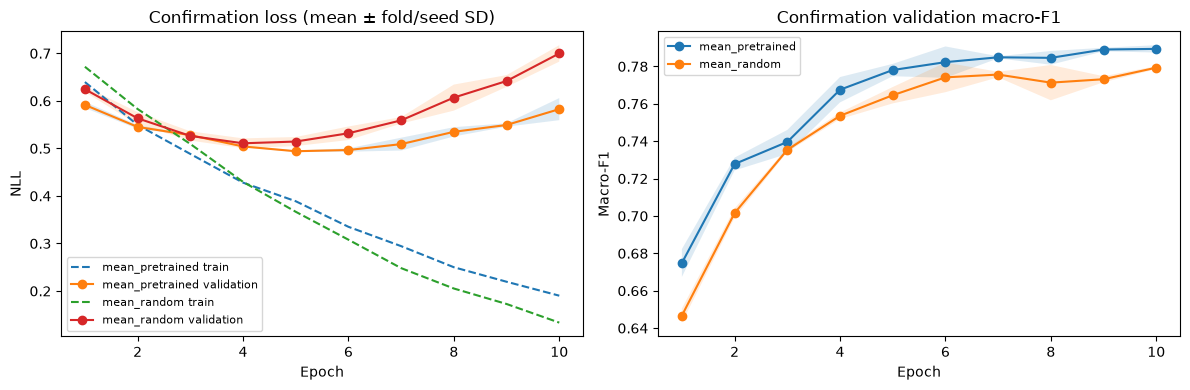

Curves are diagnostic; no confirmation epoch was selected after inspection.


In [14]:
# Q5b — matched-fold summaries, pooled OOF metrics and mandatory final learning curves
paired = neural_scores.pivot(index=["fold", "seed"], columns="name", values="macro_f1")
paired["pretrained_minus_random"] = paired.mean_pretrained - paired.mean_random
paired["word_dropout_minus_lstm"] = paired.lstm_word_dropout - paired.lstm_pretrained
display(paired.round(4))

pooled_rows = []
for (system, model_seed), group in confirmation_predictions.groupby(["system", "seed"]):
    pooled_rows.append({"system": system, "seed": model_seed,
                        **classification_scores(group.gold, group.prediction)})
pooled_oof = pd.DataFrame(pooled_rows)
display(pooled_oof[["system", "seed", "macro_f1", "accuracy",
                    "harmful_recall", "benign_fpr"]].round(4))

curve_runs = confirmation_history[
    confirmation_history.system.isin(["mean_pretrained", "mean_random"])]
curve_summary = curve_runs.groupby(["system", "epoch"]).agg(
    train_loss_mean=("train_loss", "mean"), train_loss_sd=("train_loss", "std"),
    validation_loss_mean=("validation_loss", "mean"),
    validation_loss_sd=("validation_loss", "std"),
    macro_f1_mean=("macro_f1", "mean"), macro_f1_sd=("macro_f1", "std"),
).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for system in ["mean_pretrained", "mean_random"]:
    curve = curve_summary[curve_summary.system == system]
    axes[0].plot(curve.epoch, curve.train_loss_mean, "--", label=f"{system} train")
    axes[0].plot(curve.epoch, curve.validation_loss_mean, marker="o",
                 label=f"{system} validation")
    axes[0].fill_between(curve.epoch,
                        curve.validation_loss_mean - curve.validation_loss_sd.fillna(0),
                        curve.validation_loss_mean + curve.validation_loss_sd.fillna(0), alpha=0.15)
    axes[1].plot(curve.epoch, curve.macro_f1_mean, marker="o", label=system)
    axes[1].fill_between(curve.epoch,
                        curve.macro_f1_mean - curve.macro_f1_sd.fillna(0),
                        curve.macro_f1_mean + curve.macro_f1_sd.fillna(0), alpha=0.15)
axes[0].set(title="Confirmation loss (mean ± fold/seed SD)", xlabel="Epoch", ylabel="NLL")
axes[1].set(title="Confirmation validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
for axis in axes:
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(results_folder / "confirmation_mean_pretrained_vs_random_curves.png", dpi=150)
plt.show()
print("Curves are diagnostic; no confirmation epoch was selected after inspection.")


,system,macro_f1_mean,macro_f1_fold_sd,accuracy_mean,harmful_recall_mean,benign_fpr_mean,folds
0,p1_logistic_tfidf,0.7940,0.0131,0.7940,0.7917,0.2037,2
1,mean_pretrained,0.7894,0.0020,0.7899,0.8382,0.2585,2
2,mean_pretrained_5ep,0.7894,0.0020,0.7899,0.8382,0.2585,2
3,mean_random,0.7793,0.0008,0.7796,0.7455,0.1862,2
4,lstm_pretrained,0.7524,0.0070,0.7526,0.7592,0.2540,2
5,lstm_word_dropout,0.7514,0.0261,0.7541,0.8150,0.3068,2


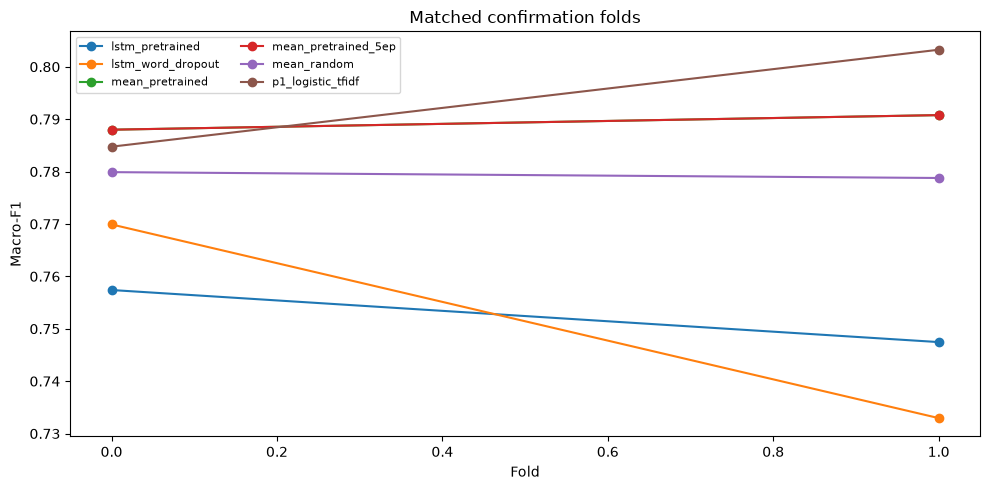

P1 versus P2 compares complete systems; pretrained versus random isolates initialization.
All locked confirmation systems are reported; no additional selection is made here.


In [15]:
# Q3/Q5 reference — one Project 1 baseline on the exact same confirmation IDs
comparison = confirmation_summary.reset_index().rename(columns={"name": "system"})
display(comparison.round(4))
plot_table = all_fold_scores.pivot(index="fold", columns="name", values="macro_f1")
ax = plot_table.plot(marker="o", figsize=(10, 5))
ax.set(title="Matched confirmation folds", xlabel="Fold", ylabel="Macro-F1")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(results_folder / "matched_confirmation_fold_scores.png", dpi=150)
plt.show()
print("P1 versus P2 compares complete systems; pretrained versus random isolates initialization.")
print("All locked confirmation systems are reported; no additional selection is made here.")


In [16]:
# Save aggregate evidence and mark the run complete only after all checks succeed
development_scores = pd.DataFrame(development_score_rows)
development_history = pd.concat(development_histories, ignore_index=True)
development_predictions = pd.concat(development_prediction_tables, ignore_index=True)

development_scores.to_csv(results_folder / "development_scores.csv", index=False)
development_history.to_csv(results_folder / "development_history.csv", index=False)
development_predictions.to_csv(results_folder / "development_predictions.csv", index=False)
confirmation_scores.to_csv(results_folder / "confirmation_scores.csv", index=False)
confirmation_history.to_csv(results_folder / "confirmation_history.csv", index=False)
confirmation_predictions.to_csv(results_folder / "confirmation_oof_predictions.csv", index=False)
confirmation_features.to_csv(results_folder / "confirmation_input_features.csv", index=False)
all_fold_scores.to_csv(results_folder / "confirmation_fold_scores.csv", index=False)
confirmation_summary.to_csv(results_folder / "confirmation_summary.csv")
paired.to_csv(results_folder / "paired_fold_seed_differences.csv")
pooled_oof.to_csv(results_folder / "pooled_oof_metrics.csv", index=False)
curve_summary.to_csv(results_folder / "confirmation_learning_curves.csv", index=False)
error_bins.to_csv(results_folder / "error_analysis_bins.csv", index=False)
lstm_data_size_initialization.to_csv(
    results_folder / "lstm_pretraining_by_data_size.csv", index=False)
correctness_scores.to_csv(results_folder / "correctness_model_scores.csv", index=False)
correctness_predictions.to_csv(
    results_folder / "correctness_model_oof_predictions.csv", index=False)
correctness_coefficients.to_csv(
    results_folder / "correctness_model_coefficients.csv", index=False)
controlled_matrix.to_csv(results_folder / "controlled_experiment_matrix.csv", index=False)

settings.update(
    status="COMPLETE", completed_at=datetime.now(timezone.utc).isoformat(),
    selected_remove_punctuation=selected_remove_punct,
    selected_embedding_learning_rate=selected_embedding_learning_rate,
    development_configurations=pool_configs + lstm_configs,
    confirmation_configurations=confirmation_configs,
    completed_development_fits=len(development_scores),
    completed_confirmation_score_rows=len(confirmation_scores),
)
(results_folder / "settings.json").write_text(json.dumps(settings, indent=2))
print("COMPLETE:", results_folder)
print('Local test: set run_mode = "cpu_test" in the setup cell and run all cells.')
print('Snellius: set run_mode = "snellius" after obtaining a GPU allocation, then run all cells.')


COMPLETE: /Users/nivya21/NLP-P1/part2/results/project2/20261119T235007628242Z
Local test: set run_mode = "cpu_test" in the setup cell and run all cells.
Snellius: set run_mode = "snellius" after obtaining a GPU allocation, then run all cells.
